# Chronos-2 zero-shot – tổng quan

**Câu hỏi:** một mô hình nền (foundation model) dự báo chuỗi thời gian, dùng ngay không huấn luyện lại,
có dự báo diện tích ngập ĐBSCL tốt hơn mốc thống kê đơn giản **AnomAR1** không?

Notebook này là điểm bắt đầu. Mỗi phần chạy hàm thật trong `src/Chronus-2/` và kết thúc bằng
dòng **Chi tiết** chỉ ra file và hàm cần mở khi muốn xem kỹ. Notebook không chứa logic riêng;
kết quả đọc từ `results/Chronus-2/` (sinh bởi `run_forecast.py` và `evaluate.py`).

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["TQDM_DISABLE"] = "1"                                   # tắt thanh tiến trình khi tải model
warnings.filterwarnings("ignore", message="IProgress not found")  # cảnh báo giao diện, không ảnh hưởng kết quả

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parents[1]          # notebooks/Chronus-2 -> gốc repo
sys.path.insert(0, str(ROOT / "src" / "Chronus-2"))
TABLES = ROOT / "results" / "Chronus-2" / "tables"
FIGURES = ROOT / "results" / "Chronus-2" / "figures"

from flood_data import load_config, load_flood_matrix, step_to_doy
from protocol import (HORIZONS, HORIZON_DAYS, anomaly, climatology, estimate_phi,
                      anom_ar1_forecast, forecast_origins, training_seasons)
from chronos_model import Chronos2ZeroShot, build_anomaly_context, load_pipeline

## 1. Kết luận một câu

In [2]:
tests = pd.read_csv(TABLES / "vs_anom_ar1.csv")
for row in tests.itertuples():
    print(f"{HORIZON_DAYS[row.h]:>2} ngày: RMSE Chronos-2 / AnomAR1 = {row.rmse_ratio:.3f}, "
          f"thắng {row.wins}/{row.n_seasons} mùa, p (t ghép cặp) = {row.p_t:.4f}, p Holm = {row.p_t_holm:.4f}")

 8 ngày: RMSE Chronos-2 / AnomAR1 = 1.024, thắng 4/11 mùa, p (t ghép cặp) = 0.3026, p Holm = 0.6051
16 ngày: RMSE Chronos-2 / AnomAR1 = 1.027, thắng 2/11 mùa, p (t ghép cặp) = 0.3455, p Holm = 0.6051
32 ngày: RMSE Chronos-2 / AnomAR1 = 1.060, thắng 2/11 mùa, p (t ghép cặp) = 0.0050, p Holm = 0.0151


Chronos-2 **không tốt hơn** AnomAR1 ở tầm nào. Ở 8 và 16 ngày khác biệt không có ý nghĩa
(nhưng cũng chưa đủ bằng chứng để gọi là "tương đương": p TOST > 0,05). Ở 32 ngày Chronos-2
**kém hơn** có ý nghĩa (RMSE cao hơn khoảng 6%, p Holm < 0,05 trong họ 3 phép so sánh này).

## 2. Bản đồ code: đọc theo thứ tự này

| Thứ tự | File | Làm gì |
|---|---|---|
| 0 | `flood_data.py` | Đọc `data/processed/level1_series.csv` thành ma trận 21 mùa × 27 bước |
| 1 | `protocol.py` | Luật chơi chung: climatology 5 mùa trước, gốc dự báo, mùa huấn luyện, AnomAR1 |
| 2 | `chronos_model.py` | Dựng ngữ cảnh anomaly, gọi Chronos-2, lấy trung vị |
| 3 | `run_forecast.py` | **Bước 1**: dự báo 11 mùa test → `predictions.csv` |
| 4 | `evaluate.py` | **Bước 2**: RMSE, kiểm định cấp mùa, bảng theo điều kiện, hình |

Chạy lại từ đầu: `python src/Chronus-2/run_forecast.py` rồi `python src/Chronus-2/evaluate.py`;
kiểm thử: `python -m pytest tests/Chronus-2`.

## 3. Dữ liệu

Mỗi ảnh MODIS 8 ngày được gộp thành một con số: diện tích ngập (km²) của ĐBSCL.
21 mùa lũ (2000–2020), mỗi mùa 27 ảnh từ ngày 153 đến ngày 361.

Chi tiết: `flood_data.py::load_flood_matrix`

Kích thước: (21, 27) (mùa × bước)


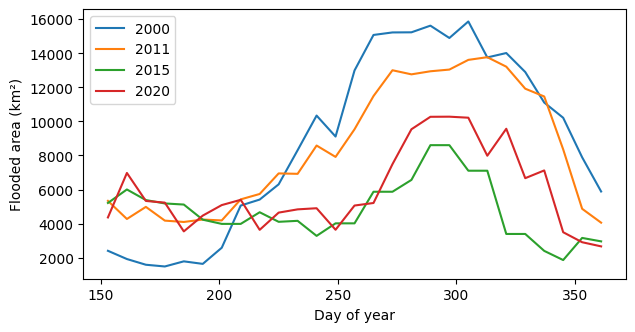

In [3]:
config = load_config("mekong")
Y = load_flood_matrix(config)
print("Kích thước:", Y.shape, "(mùa × bước)")
doys = [step_to_doy(config, s) for s in range(1, config["n_steps"] + 1)]
frame = pd.DataFrame(Y.T, index=doys, columns=range(config["first_year"], config["last_year"] + 1))
frame[[2000, 2011, 2015, 2020]].plot(figsize=(7, 3.5), xlabel="Day of year", ylabel="Flooded area (km²)");

## 4. Luật chơi chống rò rỉ

- **Climatology** (mức bình thường) của một mùa = trung bình 5 mùa **liền trước**, không gồm chính nó.
- **Anomaly** = giá trị thật − climatology; đây là phần mô hình phải dự báo.
- **Gốc dự báo** t: chỉ biết bước 1..t của mùa test; đích là bước t + h (h = 1, 2, 4 bước = 8, 16, 32 ngày).

Chi tiết: `protocol.py::climatology`, `protocol.py::anomaly`, `protocol.py::forecast_origins`

In [4]:
season = 2015
i = season - config["first_year"]
print("Climatology 2015 lấy từ các mùa:", list(range(season - 5, season)))
pd.DataFrame({"y": Y[i], "climatology": climatology(Y, i), "anomaly": anomaly(Y, i)},
             index=doys).round(0).iloc[::4]

Climatology 2015 lấy từ các mùa: [2010, 2011, 2012, 2013, 2014]


,y,climatology,anomaly
153,5213.0,5368.0,-155.0
185,5119.0,4461.0,658.0
217,4667.0,5080.0,-413.0
249,4016.0,6228.0,-2213.0
281,6565.0,11443.0,-4877.0
313,7105.0,10788.0,-3683.0
345,1861.0,4807.0,-2946.0


In [5]:
for h in HORIZONS:
    origins = forecast_origins(config["n_steps"], h)
    print(f"h = {h} ({HORIZON_DAYS[h]} ngày): gốc t = {origins.start}..{origins.stop - 1}, {len(origins)} dự báo mỗi mùa")

h = 1 (8 ngày): gốc t = 3..26, 24 dự báo mỗi mùa
h = 2 (16 ngày): gốc t = 3..25, 23 dự báo mỗi mùa
h = 4 (32 ngày): gốc t = 3..23, 21 dự báo mỗi mùa


## 5. Một dự báo làm tay: mùa 2015, gốc t = 10

1. Ngữ cảnh = anomaly của bước 1..10 (10 số).
2. Chronos-2 dự báo trung vị anomaly cho 4 bước tới.
3. Cộng lại climatology tại bước đích → km².
4. So với dòng tương ứng trong `predictions.csv`: phải trùng.

Chi tiết: `chronos_model.py::build_anomaly_context`, `chronos_model.py::Chronos2ZeroShot`, `run_forecast.py::chronos_season`

In [6]:
origin = 10
context = build_anomaly_context(Y, i, origin)
print("Ngữ cảnh (anomaly, km²):", context.round(0))

chronos = Chronos2ZeroShot(load_pipeline())     # lần đầu tải trọng số amazon/chronos-2
anomaly_forecast = chronos.forecast_anomaly(context, n_ahead=4)
c = climatology(Y, i)

saved = pd.read_csv(TABLES / "predictions.csv")
for h in HORIZONS:
    by_hand = c[origin + h - 1] + anomaly_forecast[h - 1]
    in_table = saved.query("model == 'chronos2' and season == @season and t == @origin and h == @h")["pred"].item()
    print(f"h = {h}: làm tay {by_hand:8.1f}  |  trong bảng {in_table:8.1f}  |  khớp: {abs(by_hand - in_table) < 1e-6}")

Ngữ cảnh (anomaly, km²): [ -155.  1259.    45.   728.   658.  -219.  -474.  -517.  -413. -1674.]


h = 1: làm tay   3841.9  |  trong bảng   3841.9  |  khớp: True
h = 2: làm tay   4145.8  |  trong bảng   4145.8  |  khớp: True
h = 4: làm tay   6061.0  |  trong bảng   6061.0  |  khớp: True


Cùng gốc đó với **AnomAR1**: φ ước lượng từ các mùa huấn luyện 2003–2014 (trước mùa test),
dự báo = climatology tại đích + φ^h × anomaly hôm nay.

Chi tiết: `protocol.py::estimate_phi`, `protocol.py::anom_ar1_forecast`

In [7]:
train_idx = [s - config["first_year"] for s in training_seasons(season, config["first_year"])]
for h in HORIZONS:
    phi = estimate_phi(Y, train_idx, h)
    by_hand = anom_ar1_forecast(Y, i, origin, h, phi)
    in_table = saved.query("model == 'anom_ar1' and season == @season and t == @origin and h == @h")["pred"].item()
    print(f"h = {h}: φ = {phi:.3f}  làm tay {by_hand:8.1f}  |  trong bảng {in_table:8.1f}  |  khớp: {abs(by_hand - in_table) < 1e-6}")

h = 1: φ = 0.883  làm tay   3961.3  |  trong bảng   3961.3  |  khớp: True
h = 2: φ = 0.918  làm tay   4385.3  |  trong bảng   4385.3  |  khớp: True
h = 4: φ = 0.919  làm tay   6495.2  |  trong bảng   6495.2  |  khớp: True


## 6. Kết quả tổng

RMSE gộp mọi dự báo của 11 mùa test (2010–2020). Kiểm định so sánh ở **cấp mùa** (n = 11),
vì sai số các bước trong cùng mùa tương quan mạnh.

Chi tiết: `evaluate.py::pooled_rmse`, `evaluate.py::compare_with_anom_ar1`

,1,2,4
model,,,
anom_ar1,1090.0,1375.0,1687.0
chronos2,1116.0,1412.0,1788.0


,model,h,n_seasons,rmse_ratio,wins,mse_diff_pct,mse_diff_pct_ci_low,mse_diff_pct_ci_high,p_t,p_wilcoxon,p_tost,p_t_holm
0,chronos2,1,11,1.0240,4,7.7421,-1.0148,16.4990,0.3026,0.1748,0.2157,0.6051
1,chronos2,2,11,1.0266,2,7.2345,-2.3514,16.8204,0.3455,0.1748,0.2108,0.6051
2,chronos2,4,11,1.0601,2,14.2783,4.0393,24.5173,0.0050,0.0098,0.7480,0.0151


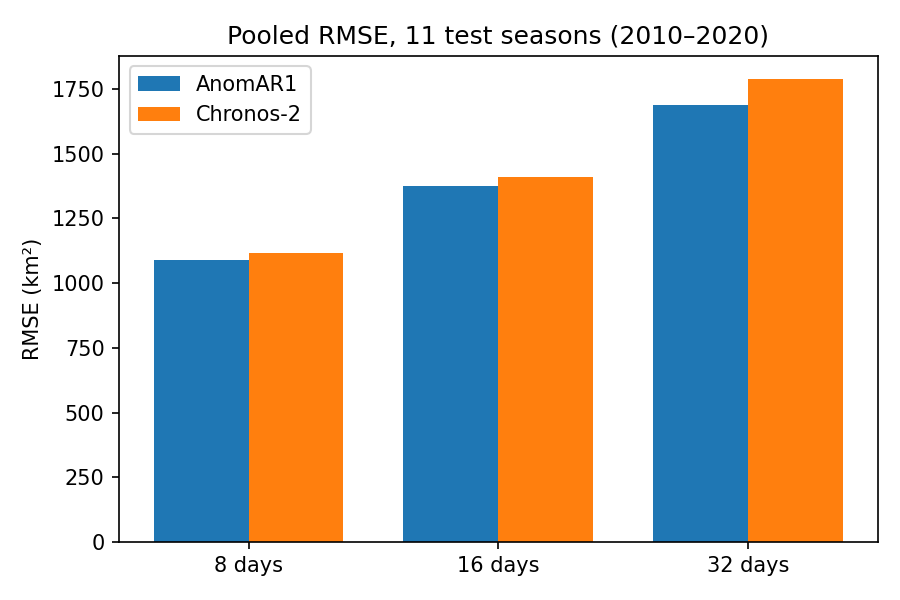

In [8]:
display(pd.read_csv(TABLES / "rmse.csv").set_index("model"))
display(tests)
display(Image(FIGURES / "rmse_by_horizon.png", width=480))

## 7. Theo điều kiện

Giai đoạn lũ và cỡ lũ (tầm 16 ngày), rồi vị trí của gốc dự báo trong mùa.

Chi tiết: `evaluate.py::add_flood_phase`, `evaluate.py::add_flood_size`, `evaluate.py::add_season_part`

In [9]:
display(pd.read_csv(TABLES / "rmse_by_phase_h2.csv").set_index("model"))
display(pd.read_csv(TABLES / "rmse_by_size_h2.csv").set_index("model"))
display(pd.read_csv(TABLES / "rmse_by_season_part.csv").set_index(["h", "season_part"]))

,rising,peak,falling
model,,,
anom_ar1,1154.0,1391.0,1578.0
chronos2,1134.0,1468.0,1633.0


,small,medium,large
model,,,
anom_ar1,1488.0,1367.0,1260.0
chronos2,1579.0,1323.0,1295.0


anom_ar1  chronos2
h season_part                    
1 t<=20           974.0    1005.0
  t>=21          1380.0    1396.0
2 t<=20          1285.0    1311.0
  t>=21          1661.0    1726.0
4 t<=20          1687.0    1703.0
  t>=21          1689.0    2236.0

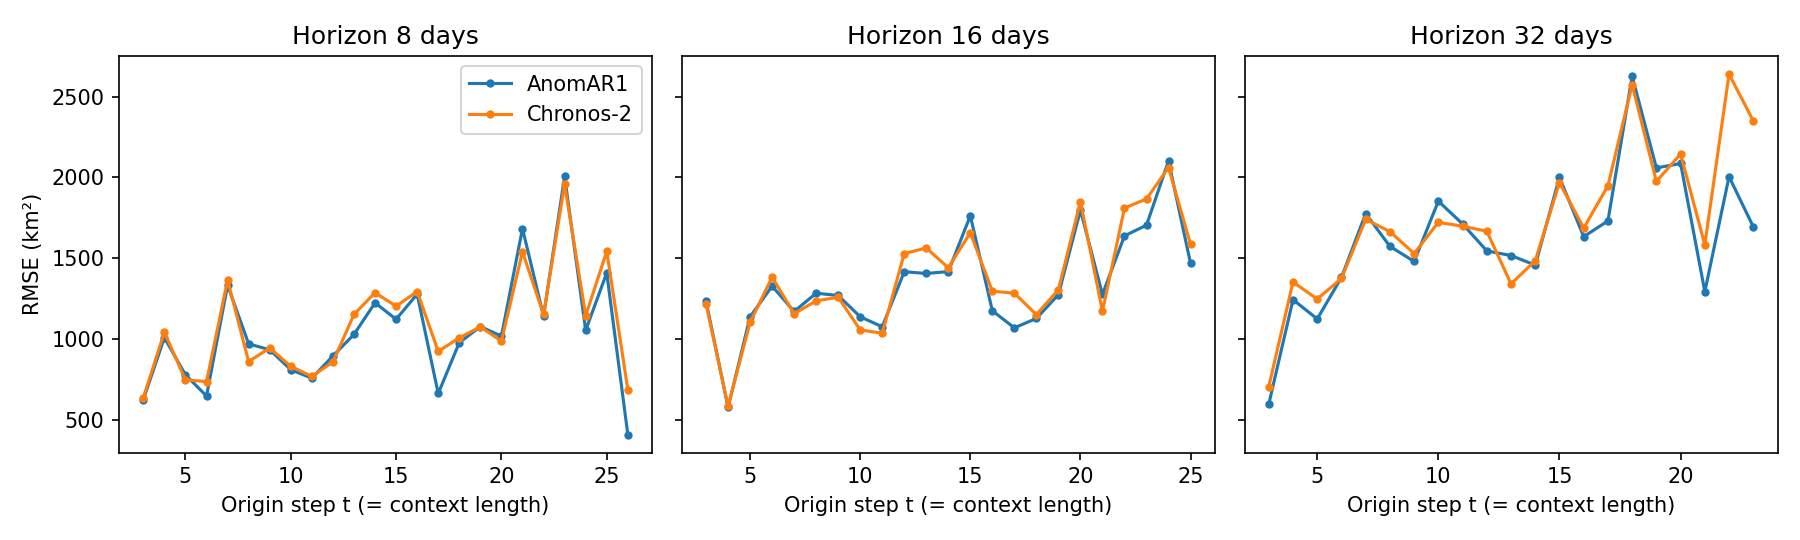

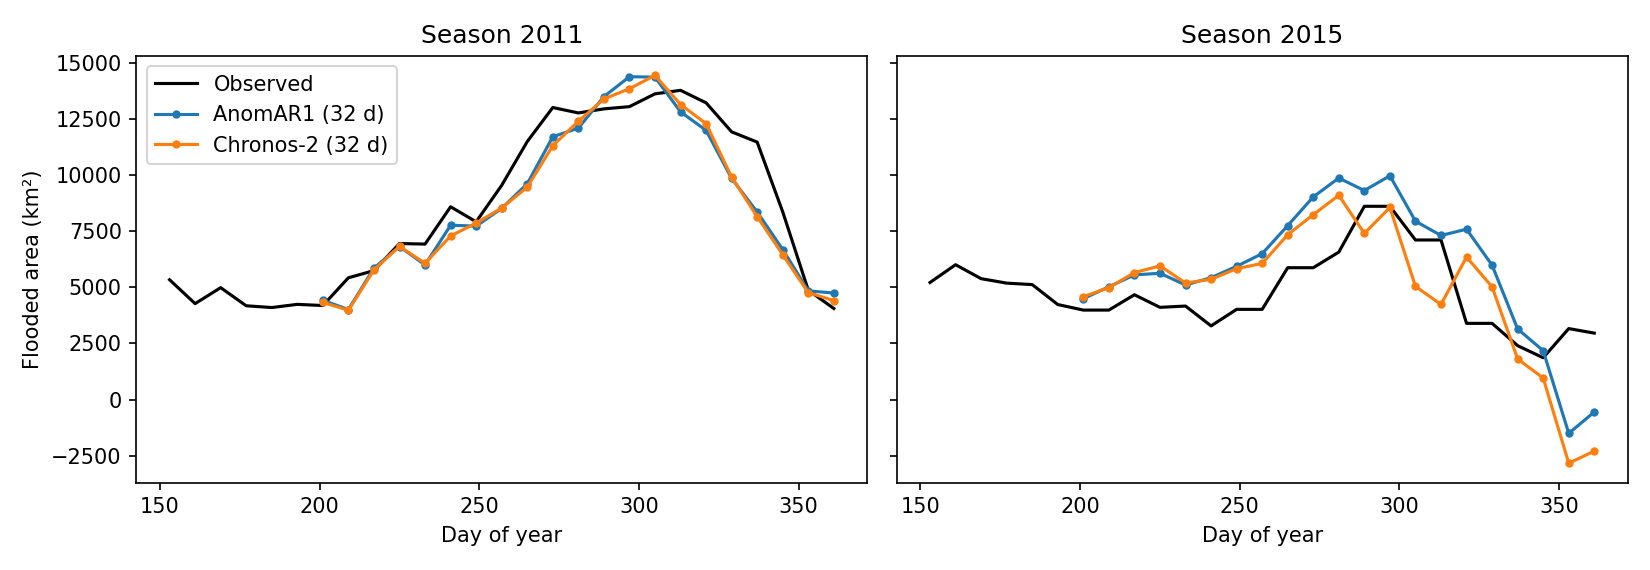

In [10]:
display(Image(FIGURES / "rmse_by_origin.png", width=900))
display(Image(FIGURES / "example_seasons.png", width=900))

**Đọc kết quả:** ở 32 ngày, khi gốc dự báo nằm ở đầu–giữa mùa (t ≤ 20) hai mô hình gần như
ngang nhau; phần Chronos-2 thua tập trung ở **cuối mùa** (t ≥ 21, đích rơi vào cuối giai đoạn
nước rút). Tức là điểm yếu **không** nằm ở ngữ cảnh ngắn đầu mùa.

## 8. Cách nói an toàn và hạn chế

- Nói: "Trên 11 mùa test, Chronos-2 zero-shot không tốt hơn AnomAR1; ở 32 ngày kém hơn có ý nghĩa."
  Không nói "foundation model kém" nói chung: chỉ một model, một cách đưa ngữ cảnh, không tinh chỉnh.
- p Holm ở đây chỉ hiệu chỉnh trong 3 phép so sánh của Chronos-2; bảng tổng hợp của nhóm dùng họ lớn hơn nên p sẽ lớn hơn.
- "Không khác có ý nghĩa" ở 8 và 16 ngày **không** có nghĩa là tương đương (p TOST > 0,05).
- Chỉ 11 mùa test, một chuỗi toàn vùng: khoảng tin cậy rộng.
- Cả hai mô hình đôi khi dự báo diện tích âm cuối mùa (không cắt về 0, giữ đúng giao thức chung).
- Mục tiêu là sản phẩm suy diễn từ ảnh MODIS (Vu et al. 2022), không phải đo trực tiếp.

Xem thêm: `src/Chronus-2/README.md`.